Dataset shape: (768, 9)
First rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Missing values in the original file: 0
Duplicate rows: 0

Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64

Zero measurements treated as missing:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI          

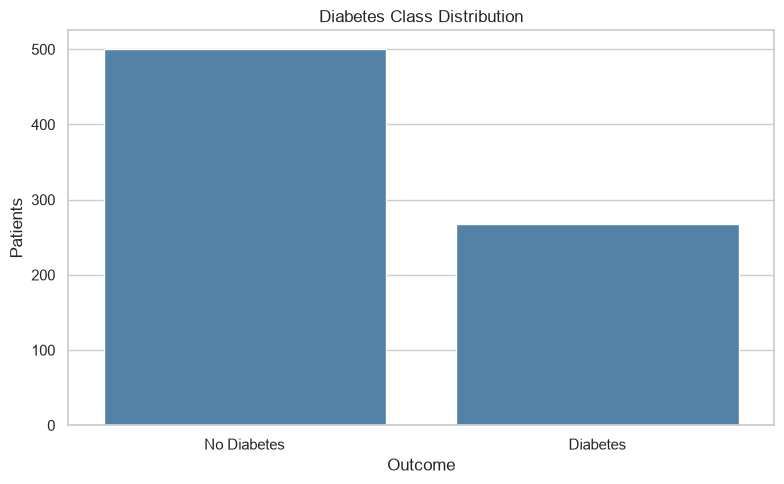

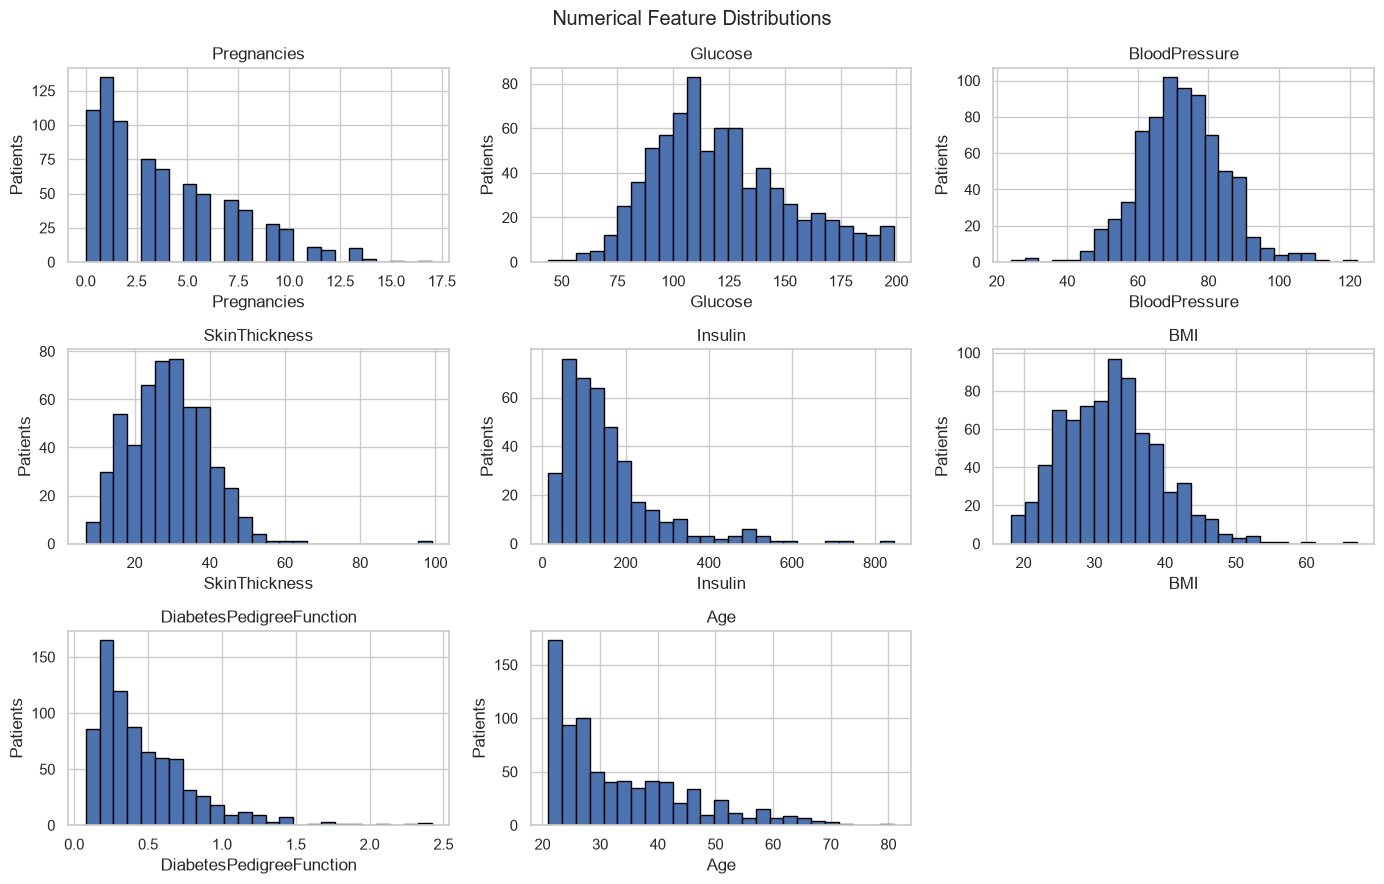

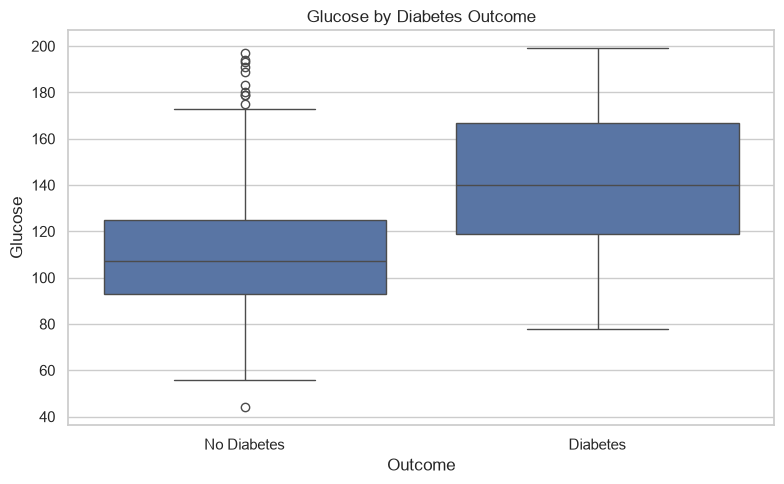

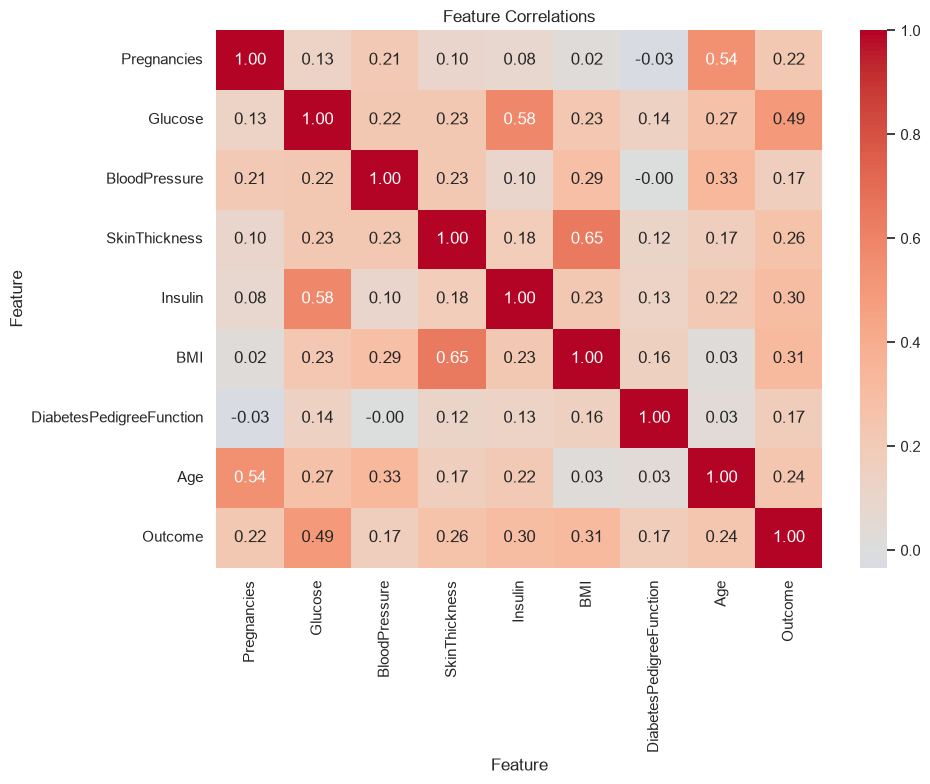

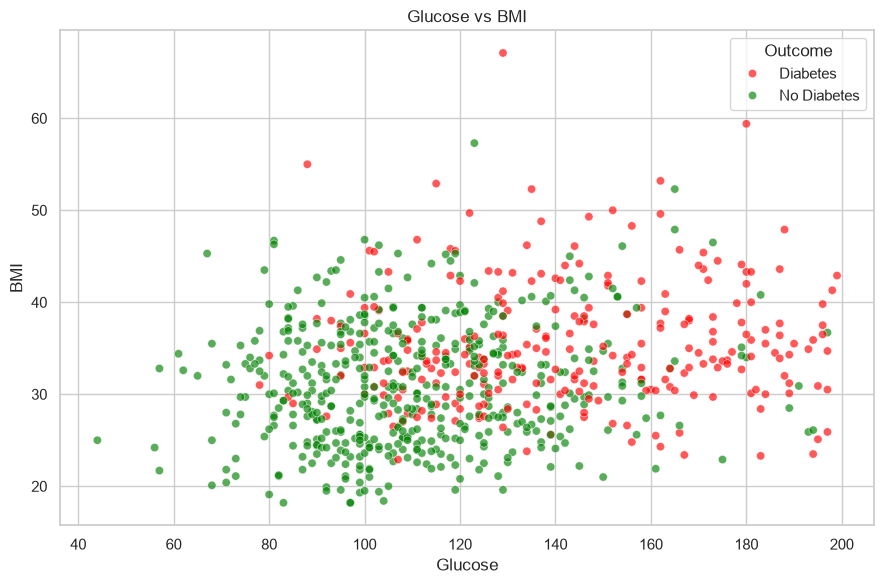

Training samples: 614
Testing samples: 154

Training medians used by the imputer:
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00
Name: Median, dtype: float64

Missing values before and after preprocessing:
                          Before  After
Pregnancies                    0      0
Glucose                        4      0
BloodPressure                 23      0
SkinThickness                175      0
Insulin                      290      0
BMI                            9      0
DiabetesPedigreeFunction       0      0
Age                            0      0


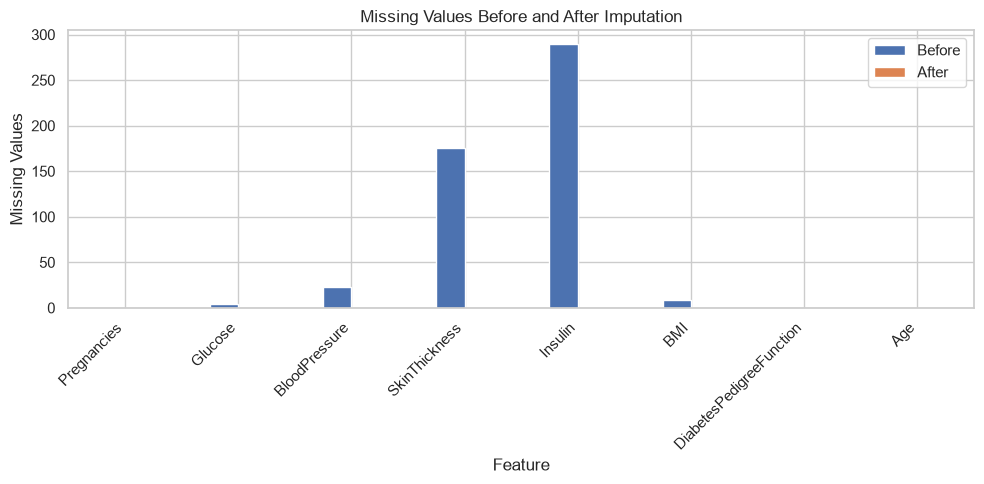

Remaining missing values: 0

Best hyperparameters: {'tree__class_weight': 'balanced', 'tree__criterion': 'gini', 'tree__max_depth': 5, 'tree__min_samples_leaf': 1}
Best CV F1: 0.6614

Best combinations by F1:
   param_tree__criterion param_tree__max_depth  param_tree__min_samples_leaf  \
60                  gini                     5                             1   
52                  gini                     3                             1   
55                  gini                     3                            10   
54                  gini                     3                             5   
53                  gini                     3                             3   
76               entropy                     3                             1   
79               entropy                     3                            10   
78               entropy                     3                             5   
82               entropy                     4                         

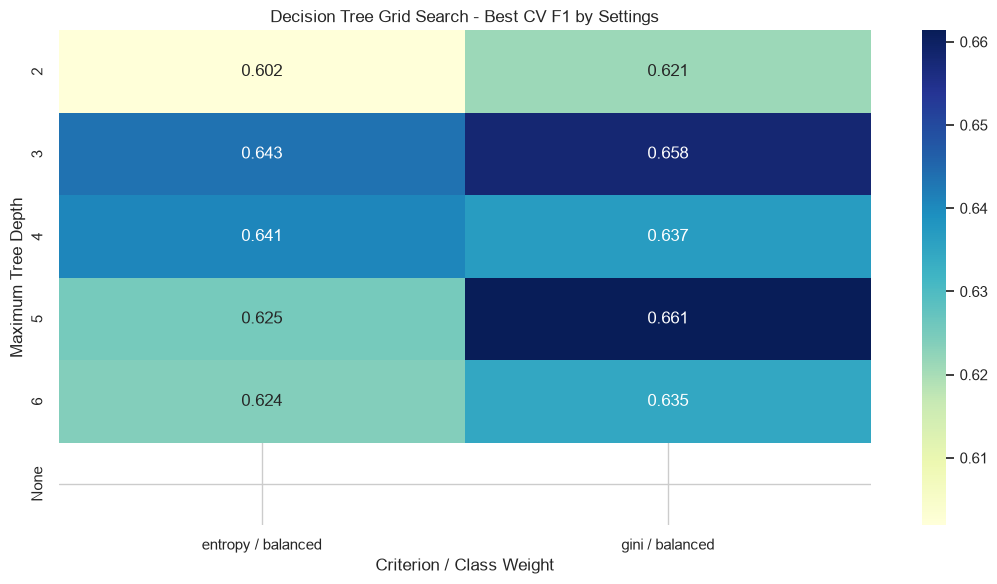


Final test results:
      Metric   Score
0   Accuracy  0.7273
1  Precision  0.6111
2     Recall  0.6111
3         F1  0.6111

Classification report:
              precision    recall  f1-score   support

 No Diabetes       0.79      0.79      0.79       100
    Diabetes       0.61      0.61      0.61        54

    accuracy                           0.73       154
   macro avg       0.70      0.70      0.70       154
weighted avg       0.73      0.73      0.73       154

Majority-class accuracy: 0.6494


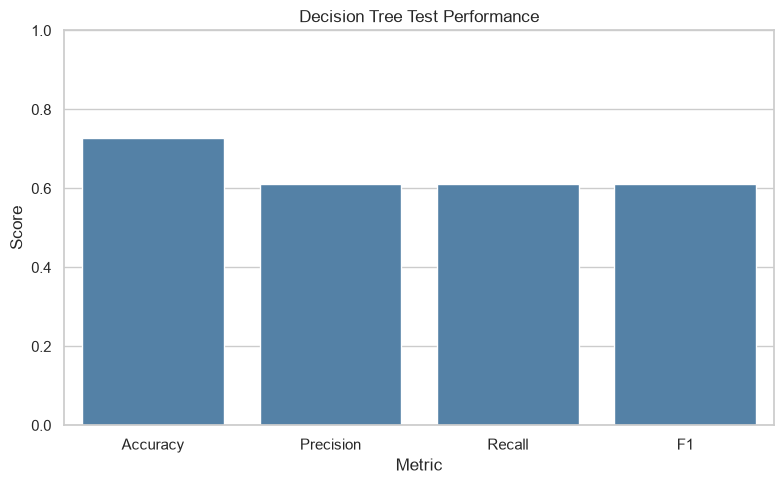

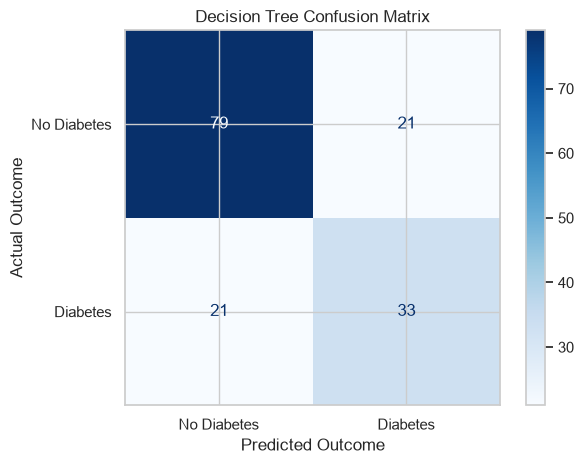

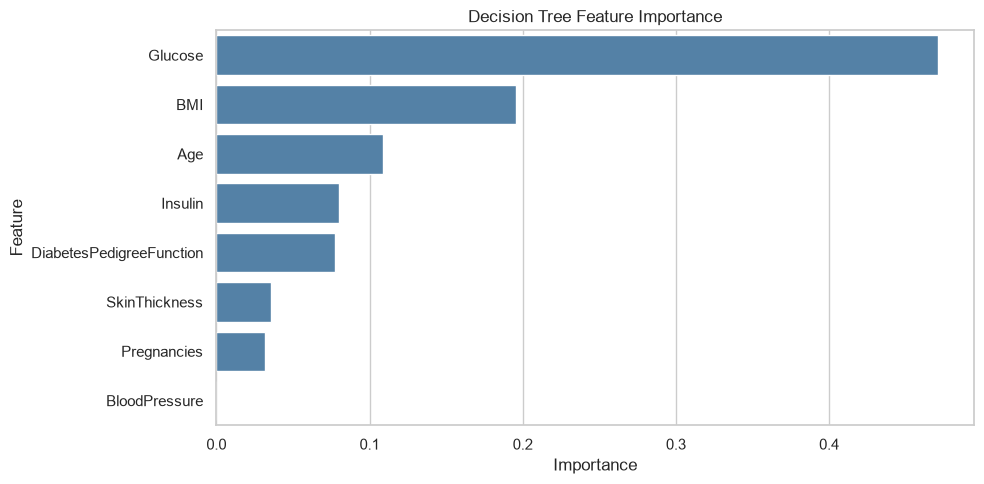

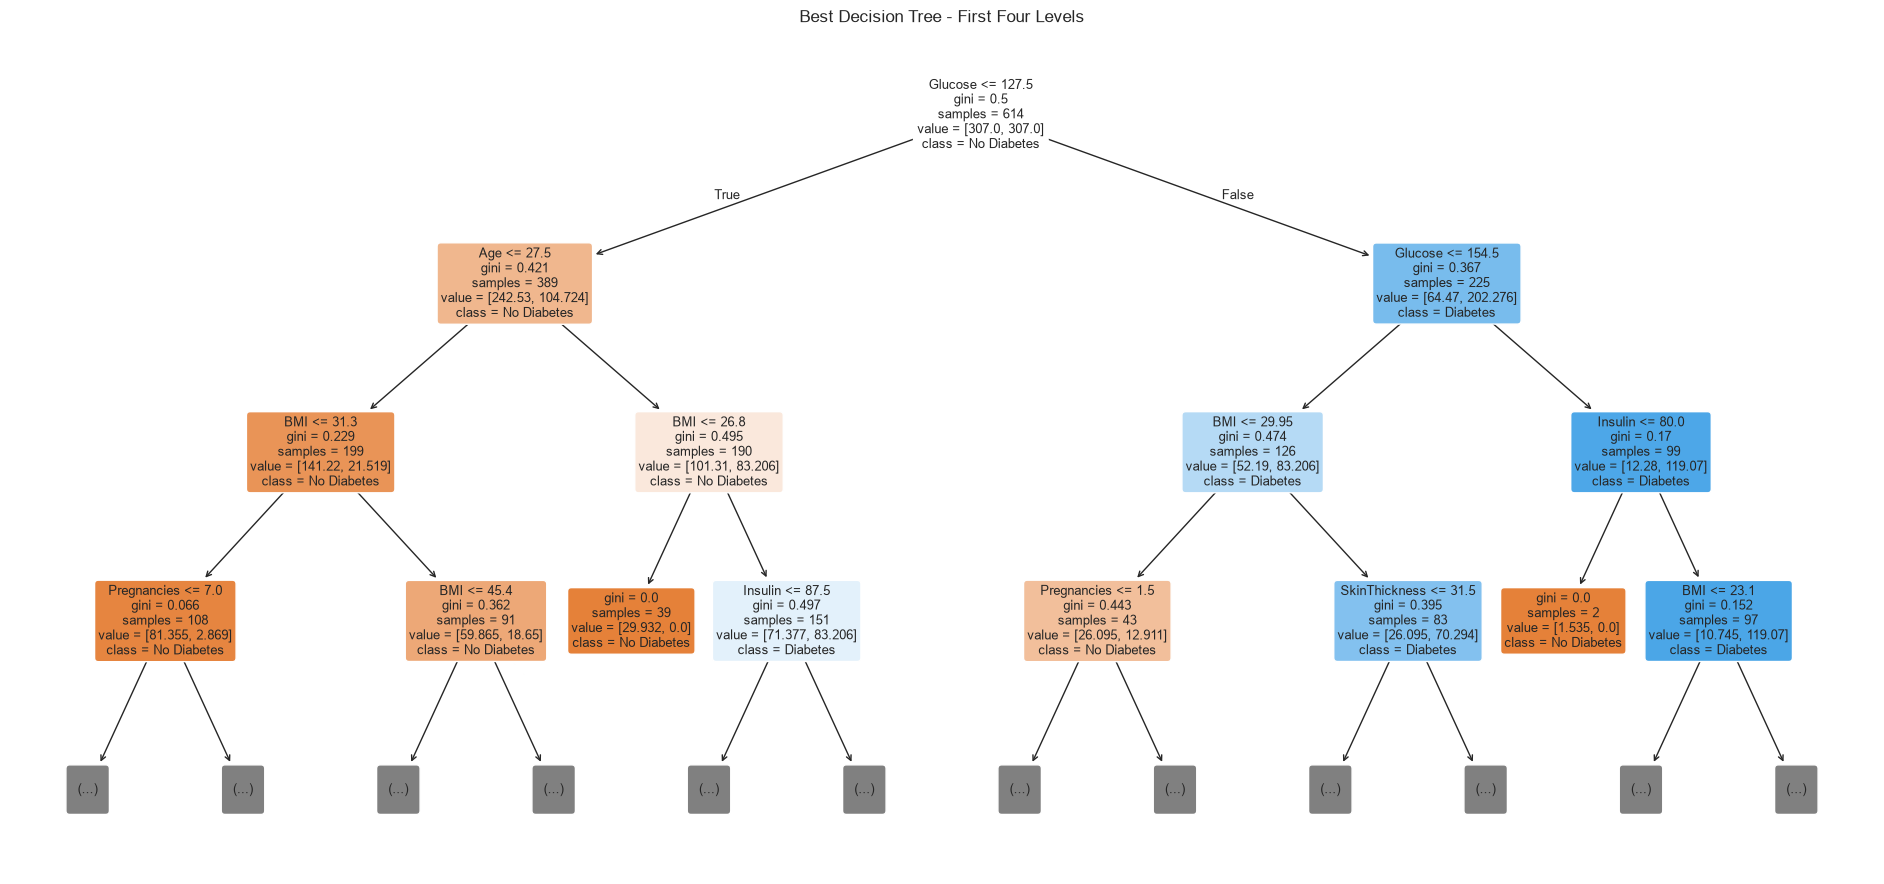


Summary:
Best parameters: {'tree__class_weight': 'balanced', 'tree__criterion': 'gini', 'tree__max_depth': 5, 'tree__min_samples_leaf': 1}
Test accuracy: 0.7273
Test F1 (diabetes): 0.6111
Test recall (diabetes): 0.6111
Test precision (diabetes): 0.6111


In [ ]:
# Student: Gleb Matyushev
# Student ID: 12552707
# Group: Whales
# Dataset: Pima Indians Diabetes
# Algorithm: Decision Tree

# I used F1-score to select the model because there are fewer positive
# diabetes cases than negative cases in the dataset.


# 1. Imports

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")


# 2. Load dataset

data_path = Path.cwd() / "data" / "diabetes.csv"

if not data_path.is_file():
    data_path = Path.cwd() / "02_Pima_Diabetes_Decision_Tree" / "data" / "diabetes.csv"

if not data_path.is_file():
    raise FileNotFoundError("Missing data/pima_diabetes.csv.")

column_names = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome",
]

# The downloaded CSV has no column names in its first row
df = pd.read_csv(data_path, header=None, names=column_names)

print("Dataset shape:", df.shape)
print("First rows:")
print(df.head())


# 3. Data inspection and cleaning

# Outcome is the correct class: 0 = no diabetes, 1 = diabetes
X = df.drop(columns="Outcome")
y = df["Outcome"]

print("\nMissing values in the original file:", X.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass distribution:")
print(y.value_counts().sort_index())

# Zero is a possible value for Pregnancies, but not for these measurements
# In this dataset, such zeros indicate missing measurements
missing_zero_columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
zero_counts = (X[missing_zero_columns] == 0).sum()
print("\nZero measurements treated as missing:")
print(zero_counts)

# Replacing known invalid zeros does not learn anything from the dataset
# We will calculate the replacement medians only after splitting
X[missing_zero_columns] = X[missing_zero_columns].replace(0, np.nan)

print("\nMissing values after cleaning:")
print(X.isna().sum())


# 4. Exploratory data analysis

# Class distribution
class_counts = y.value_counts().sort_index()
plt.figure(figsize=(8, 5))
sns.barplot(x=["No Diabetes", "Diabetes"], y=class_counts.values, color="steelblue")
plt.title("Diabetes Class Distribution")
plt.xlabel("Outcome")
plt.ylabel("Patients")
plt.tight_layout()
plt.show()


# Distribution of numerical features
hist_axes = X.hist(figsize=(14, 9), bins=25, edgecolor="black")
for ax, feature in zip(hist_axes.flat, X.columns):
    ax.set_xlabel(feature)
    ax.set_ylabel("Patients")
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()


# Compare glucose values for the two classes
plot_data = X.copy()
plot_data["Outcome"] = y.map({0: "No Diabetes", 1: "Diabetes"})
plt.figure(figsize=(8, 5))
sns.boxplot(data=plot_data, x="Outcome", y="Glucose", order=["No Diabetes", "Diabetes"])
plt.title("Glucose by Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")
plt.tight_layout()
plt.show()


# Correlations between the features and the target
plt.figure(figsize=(10, 8))
sns.heatmap(
    X.assign(Outcome=y).corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0
)
plt.title("Feature Correlations")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# Glucose and BMI colored by the outcome
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=plot_data,
    x="Glucose",
    y="BMI",
    hue="Outcome",
    palette={"No Diabetes": "green", "Diabetes": "red"},
    alpha=0.65,
)
plt.title("Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()


# 5. Train/test split

# 80% for training, 20% for final testing
# stratify=y keeps the same class ratio in both sets
# random_state makes the split reproducible
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# 6. Preprocessing

# Replace missing values using the median of each training column
# A decision tree does not need StandardScaler, since it uses value thresholds
imputer = SimpleImputer(strategy="median")

# Only for checking preprocessing; GridSearchCV will fit its own imputer
X_train_processed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

median_values = pd.Series(imputer.statistics_, index=X_train.columns, name="Median")
print("\nTraining medians used by the imputer:")
print(median_values.round(2))


# 7. Check preprocessing

missing_summary = pd.DataFrame(
    {
        "Before": X_train.isna().sum(),
        "After": X_train_processed.isna().sum(),
    }
)

print("\nMissing values before and after preprocessing:")
print(missing_summary)

missing_summary.plot.bar(figsize=(10, 5))
plt.title("Missing Values Before and After Imputation")
plt.xlabel("Feature")
plt.ylabel("Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Remaining missing values:", X_train_processed.isna().sum().sum())


# 8. Decision Tree training and Grid Search

# The imputer runs inside each cross-validation fold, avoiding data leakage
model = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeClassifier(random_state=42)),
    ]
)

# tree__ selects parameters from the "tree" step of the pipeline
# max_depth limits how many levels the tree can have
# min_samples_leaf prevents leaves with too few training observations
param_grid = {
    "tree__criterion": ["gini", "entropy"],
    "tree__max_depth": [2, 3, 4, 5, 6, None],
    "tree__min_samples_leaf": [1, 3, 5, 10],
    "tree__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# "f1" is sklearn's built-in F1 score for class 1 (diabetes)
# refit="f1" means the best model is chosen using average validation F1
scoring = {
    "accuracy": "accuracy",
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
}

grid_search = GridSearchCV(
    model, param_grid, scoring=scoring, refit="f1", cv=cv, n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\nBest hyperparameters:", grid_search.best_params_)
print("Best CV F1:", round(grid_search.best_score_, 4))

cv_results = pd.DataFrame(grid_search.cv_results_)

best_results = cv_results[
    [
        "param_tree__criterion",
        "param_tree__max_depth",
        "param_tree__min_samples_leaf",
        "param_tree__class_weight",
        "mean_test_f1",
        "mean_test_accuracy",
        "mean_test_balanced_accuracy",
    ]
].sort_values("mean_test_f1", ascending=False)

print("\nBest combinations by F1:")
print(best_results.head(10).round(3))

# Use 'No limit' as a label for max_depth=None
cv_results["depth"] = cv_results["param_tree__max_depth"].astype(str)
cv_results["settings"] = (
    cv_results["param_tree__criterion"].astype(str)
    + " / "
    + cv_results["param_tree__class_weight"].astype(str)
)

# For each combination of depth/criterion/class weight, show the best leaf size
heatmap_data = cv_results.pivot_table(
    index="depth", columns="settings", values="mean_test_f1", aggfunc="max"
)
heatmap_data = heatmap_data.reindex(["2", "3", "4", "5", "6", "None"])

plt.figure(figsize=(11, 6))
sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Decision Tree Grid Search - Best CV F1 by Settings")
plt.xlabel("Criterion / Class Weight")
plt.ylabel("Maximum Tree Depth")
plt.tight_layout()
plt.show()


# 9. Predictions and final evaluation

# best_estimator_ contains the best pipeline, retrained on all training rows
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

metrics = pd.DataFrame(
    {
        "Metric": ["Accuracy", "Precision", "Recall", "F1"],
        "Score": [accuracy, precision, recall, f1],
    }
)

print("\nFinal test results:")
print(metrics.round(4))
print("\nClassification report:")
print(
    classification_report(
        y_test, y_pred, labels=[0, 1], target_names=["No Diabetes", "Diabetes"]
    )
)

# A majority-class model is a basic accuracy baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Majority-class accuracy:", round(baseline.score(X_test, y_test), 4))

plt.figure(figsize=(8, 5))
sns.barplot(data=metrics, x="Metric", y="Score", color="steelblue")
plt.title("Decision Tree Test Performance")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

cm_display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues",
)
cm_display.ax_.set_xlabel("Predicted Outcome")
cm_display.ax_.set_ylabel("Actual Outcome")
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

# Importance is calculated from the reduction in tree impurity
importances = pd.Series(
    best_model.named_steps["tree"].feature_importances_,
    index=X.columns,
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, color="steelblue")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Show only the first levels so the tree diagram stays readable
plt.figure(figsize=(19, 9))
plot_tree(
    best_model.named_steps["tree"],
    feature_names=X.columns.tolist(),
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3,
)
plt.title("Best Decision Tree - First Four Levels")
plt.tight_layout()
plt.show()

print("\nSummary:")
print("Best parameters:", grid_search.best_params_)
print("Test accuracy:", round(accuracy, 4))
print("Test F1 (diabetes):", round(f1, 4))
print("Test recall (diabetes):", round(recall, 4))
print("Test precision (diabetes):", round(precision, 4))